**Data Loading (kaggle)**

In [1]:
from google.colab import userdata

kaggle_secret = userdata.get("kaggle_lending_club_dataset")
print(type(kaggle_secret))


<class 'str'>


In [2]:
import json
import os

# Instead of parsing, create the dictionary directly, assuming kaggle_secret is the API key.
# You will need to replace "your_kaggle_username" with your actual Kaggle username.
kaggle_dict = {
    "username": "kaggle_lending_club_datasete", # Placeholder: please replace with your actual Kaggle username
    "key": kaggle_secret
}

# Create Kaggle config directory
os.makedirs("/root/.kaggle", exist_ok=True)

# Write kaggle.json
with open("/root/.kaggle/kaggle.json", "w") as f:
    json.dump(kaggle_dict, f)

# Set correct permissions
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("kaggle.json configured securely")

kaggle.json configured securely


In [3]:
!pip install -q kaggle

In [4]:
!kaggle datasets list | head

ref                                                     title                                           size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------  ----------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
neurocipher/heartdisease                                Heart Disease                                   3491  2025-12-11 15:29:14.327000           2114        168  1.0              
neurocipher/student-performance                         Student Performance                            49705  2025-12-12 12:06:28.973000           1261        106  1.0              
dansbecker/powerlifting-database                        powerlifting-database                        9277600  2019-04-30 21:07:41.560000          24255        351  0.5882353        
rtatman/188-million-us-wildfires                        1.88 Million US Wildfires         

In [5]:
!mkdir -p dataset

!kaggle datasets download \
  -d gabrieloliveirasan/lending-club-credit-risk \
  -p dataset

Dataset URL: https://www.kaggle.com/datasets/gabrieloliveirasan/lending-club-credit-risk
License(s): unknown
 74% 77.0M/104M [00:00<00:00, 804MB/s]
100% 104M/104M [00:00<00:00, 849MB/s] 


In [6]:
!unzip -o dataset/lending-club-credit-risk.zip -d dataset

Archive:  dataset/lending-club-credit-risk.zip
  inflating: dataset/loan.csv        


In [7]:
!ls dataset

lending-club-credit-risk.zip  loan.csv


# **Data cleaning**

In [8]:
# Colab-specific installs
!pip install -q xgboost imbalanced-learn

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42


In [9]:
!ls dataset

lending-club-credit-risk.zip  loan.csv


In [10]:
df = pd.read_csv(
    "/content/dataset/loan.csv",
    engine="python",
    sep=",",
    encoding="utf-8",
    on_bad_lines="skip"
)

assert 'loan_status' in df.columns, "loan_status column missing"
print("Loaded shape:", df.shape)

# Drop free-text columns early
DROP_TEXT = ['desc', 'title', 'emp_title']
df.drop(columns=[c for c in DROP_TEXT if c in df.columns], inplace=True)


Loaded shape: (833400, 74)


In [11]:
print(df.isna().mean().sort_values(ascending=False).head(10))

dti_joint                    0.999390
annual_inc_joint             0.999388
verification_status_joint    0.999388
il_util                      0.977858
mths_since_rcnt_il           0.975247
inq_fi                       0.974578
open_acc_6m                  0.974578
total_cu_tl                  0.974578
all_util                     0.974578
max_bal_bc                   0.974578
dtype: float64


**Define Target Variable**

In [12]:
GOOD = ["Fully Paid", "Current"]
BAD = [
    "Charged Off",
    "Default",
    "Late (31-120 days)",
    "Does not meet the credit policy. Status:Charged Off"
]

df = df[df['loan_status'].isin(GOOD + BAD)].copy()

df['credit_risk'] = df['loan_status'].apply(
    lambda x: 1 if x in BAD else 0
)

print(df['credit_risk'].value_counts(normalize=True))

credit_risk
0    0.935902
1    0.064098
Name: proportion, dtype: float64


**Drop leakage + identifiers (critical)**

In [13]:
LEAKAGE_COLS = [
    'loan_status',
    'total_rec_late_fee',
    'total_pymnt',
    'total_pymnt_inv',
    'total_rec_prncp',
    'total_rec_int',
    'recoveries',
    'collection_recovery_fee',
    'last_pymnt_amnt',
    'next_pymnt_d',
    'out_prncp',
    'out_prncp_inv'
]

ID_COLS = ['id', 'member_id']

df.drop(
    columns=[c for c in LEAKAGE_COLS + ID_COLS if c in df.columns],
    inplace=True
)

**Date handling**

In [14]:
DATE_COLS = [
    'issue_d',
    'earliest_cr_line',
    'last_credit_pull_d'
]

for col in DATE_COLS:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# Feature engineering: credit history length
if 'earliest_cr_line' in df.columns and 'issue_d' in df.columns:
    df['credit_history_years'] = (
        (df['issue_d'] - df['earliest_cr_line']).dt.days / 365
    )

df.drop(columns=[c for c in DATE_COLS if c in df.columns], inplace=True)


**Drop remaining leakage columns**


*    after finding out it during extract importance


```
last_pymnt_d_Jan-2016
last_pymnt_d_Dec-2015
last_pymnt_d_Nov-2015
...
```

This is not normal for a credit risk model.

Why?



```
last_pymnt_d = date of last payment
```



That means:


*   It happens after the loan is issued
*   It is strongly correlated with default
*   It directly encodes how the loan performed

In other words:

model is partially cheating.

(classic target leakage)





In [15]:
POST_ORIGINATION_DATE_COLS = [
    'last_pymnt_d',
    'next_pymnt_d'
]

df.drop(
    columns=[c for c in POST_ORIGINATION_DATE_COLS if c in df.columns],
    inplace=True
)

for col in df.columns:
    assert not col.startswith('last_pymnt'), f"Leakage column detected: {col}"

**Split features & target**

In [16]:
X = df.drop(columns='credit_risk')
y = df['credit_risk']

cat_cols = X.select_dtypes(include='object').columns.tolist()
num_cols = X.select_dtypes(exclude='object').columns.tolist()

print(f"Categorical: {len(cat_cols)}")
print(f"Numerical: {len(num_cols)}")

Categorical: 15
Numerical: 39


# Data Preprocessing & Encoding
**Train/Test Split**

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


**Preprocessing pipelines (memory-safe)**

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=True,
        min_frequency=50
    ))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])


# Model Training & Validation
**Logistic Regression (baseline)**

In [19]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

lr_pipeline = ImbPipeline([
    ('preprocess', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        n_jobs=-1
    ))
])

lr_pipeline.fit(X_train, y_train)

lr_pred = lr_pipeline.predict_proba(X_test)[:, 1]

print("Logistic ROC-AUC:", roc_auc_score(y_test, lr_pred))
print(classification_report(y_test, lr_pipeline.predict(X_test)))


Logistic ROC-AUC: 0.7502304841994851
              precision    recall  f1-score   support

           0       0.98      0.41      0.58    152662
           1       0.09      0.90      0.17     10455

    accuracy                           0.44    163117
   macro avg       0.54      0.65      0.37    163117
weighted avg       0.93      0.44      0.55    163117



**XGBoost (primary model)**

In [20]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', XGBClassifier(
        scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum(),
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_train, y_train)

xgb_pred = xgb_pipeline.predict_proba(X_test)[:, 1]

print("XGBoost ROC-AUC:", roc_auc_score(y_test, xgb_pred))
print(classification_report(y_test, xgb_pipeline.predict(X_test)))


XGBoost ROC-AUC: 0.7795303238360911
              precision    recall  f1-score   support

           0       0.98      0.66      0.78    152662
           1       0.13      0.76      0.22     10455

    accuracy                           0.66    163117
   macro avg       0.55      0.71      0.50    163117
weighted avg       0.92      0.66      0.75    163117



# Cost-Sensitive Threshold Optimization
**Define Costs & Sweep Thresholds**

In [52]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

COST_FN = 10   # approving a bad loan
COST_FP = 1    # rejecting a good loan

**Evaluate loss across thresholds**

In [53]:
thresholds = np.linspace(0.01, 0.99, 99)

losses = []

for t in thresholds:
    y_pred = (xgb_pred >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    total_loss = fn * COST_FN + fp * COST_FP

    losses.append({
        "threshold": t,
        "loss": total_loss,
        "fp": fp,
        "fn": fn
    })

loss_df = pd.DataFrame(losses)

**Find optimal threshold**

In [54]:
best_row = loss_df.loc[loss_df['loss'].idxmin()]
optimal_threshold = float(best_row['threshold'])

best_row

,55
threshold,0.56
loss,74544.00
fp,39254.00
fn,3529.00


**Visualize expected loss vs threshold**

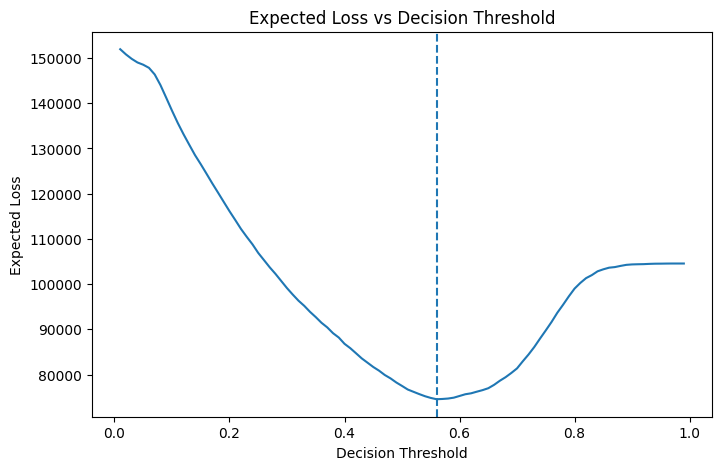

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(loss_df['threshold'], loss_df['loss'])
plt.axvline(optimal_threshold, linestyle='--')
plt.xlabel("Decision Threshold")
plt.ylabel("Expected Loss")
plt.title("Expected Loss vs Decision Threshold")
plt.show()

**Evaluate model at cost-optimal threshold**



> Instead of using a fixed 0.5 cutoff, we optimized the decision threshold using a cost-sensitive framework where approving a defaulting loan was assumed to be significantly more expensive than rejecting a good one. This aligns the model decision rule with business risk rather than purely statistical metrics.



# Probability Calibration
**Calibrate Probabilities**

In [51]:
from sklearn.calibration import CalibratedClassifierCV

X_train_trans = xgb_pipeline.named_steps['preprocess'].transform(X_train)
X_test_trans = xgb_pipeline.named_steps['preprocess'].transform(X_test)

calibrated_xgb = CalibratedClassifierCV(
    estimator=xgb_pipeline.named_steps['model'],
    method='isotonic',
    cv=3
)

calibrated_xgb.fit(X_train_trans, y_train)
cal_probs = calibrated_xgb.predict_proba(X_test_trans)[:, 1]

# Expected Loss & Credit Policy Analysis
**Compute Expected Loss per loan**

In [41]:
LGD = 0.9

# Use calibrated probabilities if available
try:
    pd_scores = cal_probs
except NameError:
    pd_scores = xgb_pred

el_df = X_test.copy()

el_df['PD'] = pd_scores
el_df['EAD'] = df.loc[X_test.index, 'loan_amnt']
el_df['Expected_Loss'] = el_df['PD'] * LGD * el_df['EAD']

**Policy decision using Expected Loss**



> Approve loan only if expected loss < 20% of loan amount



In [42]:
EL_RATIO_THRESHOLD = 0.20

el_df['approve_el'] = (
    el_df['Expected_Loss'] / el_df['EAD'] < EL_RATIO_THRESHOLD
).astype(int)


**Evaluate EL-based policy**

In [43]:
from sklearn.metrics import confusion_matrix

y_pred_el = el_df['approve_el'].values

cm_el = confusion_matrix(y_test, y_pred_el)

pd.DataFrame(
    cm_el,
    index=["Actual Good (0)", "Actual Bad (1)"],
    columns=["Approved (0)", "Rejected (1)"]
)

,Approved (0),Rejected (1)
Actual Good (0),108751,43911
Actual Bad (1),10149,306


**Compare policies**

Approval rate comparison

In [46]:
print("Approval rate (threshold-based):", (y_pred_cost == 0).mean())
print("Approval rate (EL-based):", (y_pred_el == 0).mean())

Approval rate (threshold-based): 0.7168903302537443
Approval rate (EL-based): 0.7289246369170596


**Bad-loan approval rate**

In [50]:
bad_approval_rate = (
    ((y_test == 1) & (y_pred_el == 1)).sum() / (y_test == 1).sum()
)

print("Bad loan approval rate (EL policy):", bad_approval_rate)

Bad loan approval rate (EL policy): 0.02926829268292683


**Policy curve**

In [48]:
thresholds = np.linspace(0.05, 0.5, 20)

policy_records = []

for t in thresholds:
    approve = (el_df['Expected_Loss'] / el_df['EAD'] < t)

    approval_rate = approve.mean()
    bad_rate = ((approve) & (y_test == 1)).sum() / (y_test == 1).sum()

    policy_records.append({
        "EL_threshold": t,
        "approval_rate": approval_rate,
        "bad_approval_rate": bad_rate
    })

policy_df = pd.DataFrame(policy_records)
policy_df

,EL_threshold,approval_rate,bad_approval_rate
0,0.050000,0.027416,0.000000
1,0.073684,0.057106,0.001339
2,0.097368,0.104679,0.004591
3,0.121053,0.145938,0.008513
4,0.144737,0.184334,0.014538
5,0.168421,0.221945,0.019799
6,0.192105,0.258961,0.026973
7,0.215789,0.294353,0.036346
8,0.239474,0.328316,0.045242
9,0.263158,0.361495,0.057293


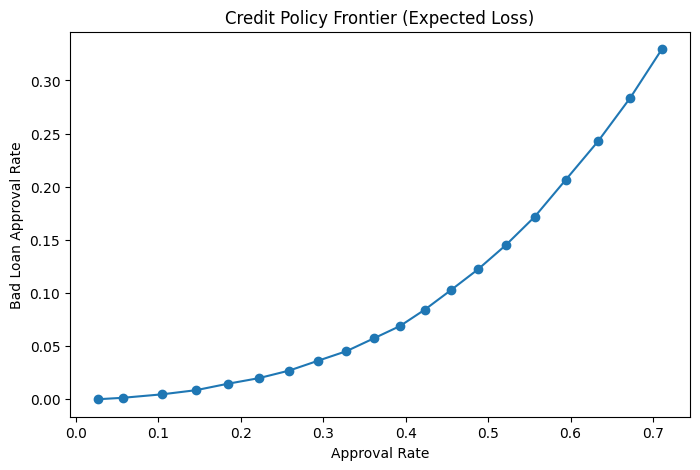

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(policy_df['approval_rate'], policy_df['bad_approval_rate'], marker='o')
plt.xlabel("Approval Rate")
plt.ylabel("Bad Loan Approval Rate")
plt.title("Credit Policy Frontier (Expected Loss)")
plt.show()

**Feature importance**
---

Extract feature names



In [26]:
num_features = num_cols

cat_features = (
    xgb_pipeline.named_steps['preprocess']
    .named_transformers_['cat']
    .named_steps['encoder']
    .get_feature_names_out(cat_cols)
)

feature_names = np.concatenate([num_features, cat_features])

**Importance table**

In [27]:
importances = xgb_pipeline.named_steps['model'].feature_importances_

fi = (
    pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    })
    .sort_values("importance", ascending=False)
    .head(20)
)

fi

,feature,importance
3,int_rate,0.037703
968,initial_list_status_f,0.037268
61,sub_grade_C4,0.035860
43,grade_C,0.032315
62,sub_grade_C5,0.030498
42,grade_B,0.023470
990,inq_last_12m;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;;...,0.022022
41,grade_A,0.021114
45,grade_E,0.017597
55,sub_grade_B3,0.016690


**SHAP explainability**

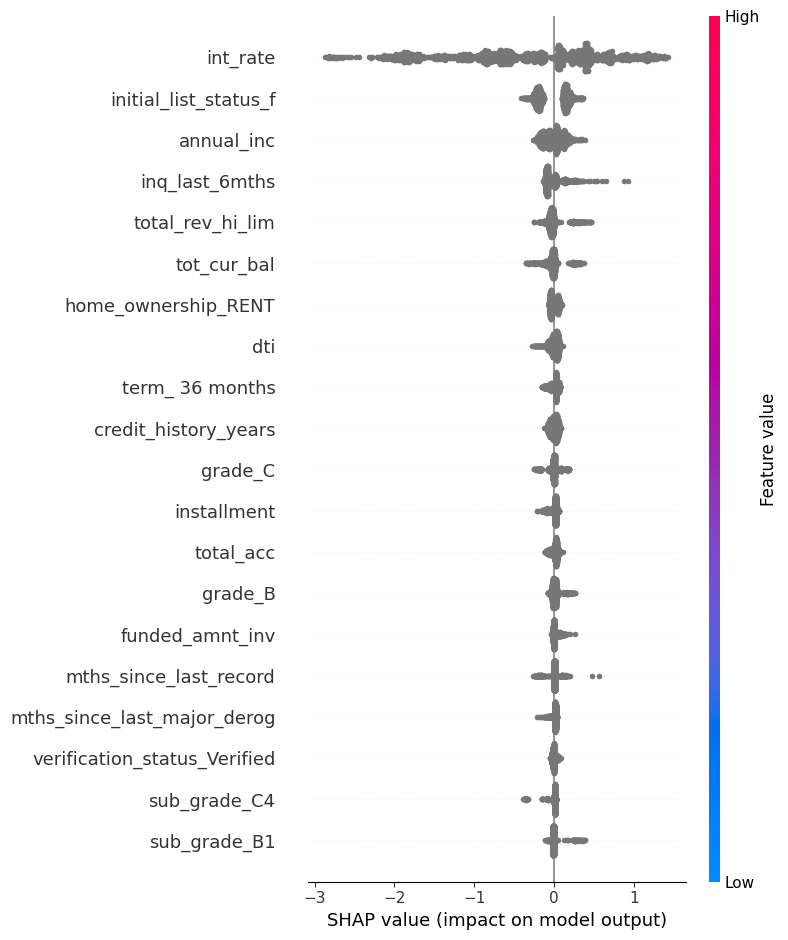

In [28]:
!pip install -q shap
import shap

X_sample = X_test.sample(2000, random_state=42)
X_transformed = xgb_pipeline.named_steps['preprocess'].transform(X_sample)

explainer = shap.TreeExplainer(xgb_pipeline.named_steps['model'])
shap_values = explainer.shap_values(X_transformed)

shap.summary_plot(shap_values, X_transformed, feature_names=feature_names)

**Save final model**

In [36]:
import joblib

joblib.dump(xgb_pipeline, "credit_risk_xgboost_final.pkl")
joblib.dump(optimal_threshold, "decision_threshold.pkl")

print("Model and threshold saved.")

Model and threshold saved.


In [37]:
assert 0 < optimal_threshold < 1
assert not np.isnan(xgb_pred).any()
assert set(y_test.unique()) == {0,1}

print("All final checks passed.")

All final checks passed.


# Conclusion

This project demonstrates how credit risk modeling can be extended beyond prediction into cost-aware decisioning and expected loss–based credit policy design.

In [38]:
# import dill

# # Save the entire session state
# dill.dump_session('credit_risk1.pkl')

# print("Current session state saved to credit_risk1.pkl.")

Current session state saved to credit_risk1.pkl.


In [39]:
# import dill
# import os

# session_file_path = 'credit_risk1.pkl'

# if os.path.exists(session_file_path):
#     print(f"Attempting to load session from {session_file_path}...")
#     dill.load_session(session_file_path)
#     print("Session successfully loaded!")
# else:
#     print(f"Error: Session file '{session_file_path}' not found.")

Attempting to load session from credit_risk1.pkl...
Session successfully loaded!
